# Student Baseline

KD 없이 정답 레이블만으로 MobileNetV3-Large를 학습한다.

## 1. GPU와 텐서

- 텐서와 모델은 CPU 또는 GPU 메모리에 있으며, 연산에 쓰는 데이터는 같은 장치에 있어야 한다.
- `.to(device)`는 지정한 장치로 복사한 새 텐서를 돌려준다.

In [7]:
# GPU를 사용할 수 있으면 GPU를, 없으면 CPU를 사용한다.
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)
print("torch:", torch.__version__)
if device.type == "cuda":
    print("GPU 이름:", torch.cuda.get_device_name(0))

device: cuda
torch: 2.11.0+cu128
GPU 이름: NVIDIA GeForce RTX 5070 Ti


In [8]:
# CPU에서 배치와 같은 형태의 텐서를 만들고 GPU로 옮긴다.
x = torch.randn(32, 3, 224, 224)
print("옮기기 전:", x.device)

x = x.to(device)
print("옮긴 후:", x.device)
print("shape:", x.shape, "dtype:", x.dtype)

옮기기 전: cpu
옮긴 후: cuda:0
shape: torch.Size([32, 3, 224, 224]) dtype: torch.float32


In [9]:
# 텐서가 차지하는 메모리를 계산값과 GPU 측정값으로 비교한다.
expected_mb = 32 * 3 * 224 * 224 * 4 / 1024**2
print(f"계산한 크기: {expected_mb:.2f} MB")

if device.type == "cuda":
    print(f"GPU 할당량: {torch.cuda.memory_allocated() / 1024**2:.2f} MB")

계산한 크기: 18.38 MB
GPU 할당량: 18.38 MB


In [10]:
# 결과를 다시 대입하지 않으면 원래 텐서의 장치가 바뀌지 않는다.
y = torch.randn(4, 3)
y.to(device)
print("대입하지 않은 y:", y.device)

y = y.to(device)
print("대입한 y:", y.device)

대입하지 않은 y: cpu
대입한 y: cuda:0


### 학습 seed

- 마지막 층 초기화, Dropout, DataLoader의 섞는 순서가 모두 난수를 사용한다.
- 분할 seed(42)와 별개로 학습 seed를 관리한다. 아래 값은 연습용이며, 본 실험의 학습 seed와 반복 횟수는 팀에서 정한 뒤 기록한다.

In [11]:
# 학습에 쓰이는 난수를 고정하는 함수를 정의하고 실행한다.
import random

def set_seed(seed):
    random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

train_seed = 0
set_seed(train_seed)
print("학습 seed:", train_seed)

학습 seed: 0


## 2. 모델 준비

- 사전학습 가중치: ImageNet 1000개 클래스로 학습된 MobileNetV3-Large를 시작점으로 사용한다.
- 분류층 교체: 마지막 층의 출력을 1000개에서 CUB의 200개로 바꾼다. 교체한 층만 무작위로 초기화된다.

In [12]:
# 사전학습 가중치를 명시하여 MobileNetV3-Large를 불러온다.
from torchvision import models

weights = models.MobileNet_V3_Large_Weights.IMAGENET1K_V2
model = models.mobilenet_v3_large(weights=weights)

print("가중치:", weights)
print(model.classifier)

가중치: MobileNet_V3_Large_Weights.IMAGENET1K_V2
Sequential(
  (0): Linear(in_features=960, out_features=1280, bias=True)
  (1): Hardswish()
  (2): Dropout(p=0.2, inplace=True)
  (3): Linear(in_features=1280, out_features=1000, bias=True)
)


In [13]:
# 교체 전 마지막 층의 입력과 출력 크기를 확인한다.
old_head = model.classifier[3]
print("교체 전:", old_head)
print("입력 특징 수:", old_head.in_features)
print("출력 클래스 수:", old_head.out_features)

교체 전: Linear(in_features=1280, out_features=1000, bias=True)
입력 특징 수: 1280
출력 클래스 수: 1000


In [14]:
# 마지막 층을 CUB의 200개 클래스용으로 교체하고 GPU로 옮긴다.
import torch.nn as nn

num_classes = 200
model.classifier[3] = nn.Linear(old_head.in_features, num_classes)
model = model.to(device)

print("교체 후:", model.classifier[3])
print("모델 장치:", next(model.parameters()).device)

교체 후: Linear(in_features=1280, out_features=200, bias=True)
모델 장치: cuda:0


In [15]:
# 전체 파라미터 수와 학습 대상 파라미터 수를 센다.
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"전체 파라미터: {total_params:,}")
print(f"학습 대상 파라미터: {trainable_params:,}")
print(f"교체한 층의 파라미터: {sum(p.numel() for p in model.classifier[3].parameters()):,}")

전체 파라미터: 4,458,232
학습 대상 파라미터: 4,458,232
교체한 층의 파라미터: 256,200


## 3. 데이터 연결과 배치 통과

`dataLoader.ipynb`의 데이터 준비, 전처리, Dataset, DataLoader 셀을 가져온다. 시각화 셀은 제외한다.

In [16]:
# 라이브러리를 불러오고 데이터 위치를 지정한다.
from pathlib import Path
import random
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from torchvision import transforms
from torchvision.transforms import functional as TF
from torch.utils.data import Dataset, DataLoader

# 프로젝트 루트 또는 notebooks 폴더에서 데이터 경로를 찾는다.
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

data_dir = project_root / "data" / "CUB_200_2011" / "CUB_200_2011"
image_list = (data_dir / "images.txt").read_text().splitlines()

print("이미지 목록 수:", len(image_list))
print(image_list[:3])


이미지 목록 수: 11788
['1 001.Black_footed_Albatross/Black_Footed_Albatross_0046_18.jpg', '2 001.Black_footed_Albatross/Black_Footed_Albatross_0009_34.jpg', '3 001.Black_footed_Albatross/Black_Footed_Albatross_0002_55.jpg']


In [17]:
# 이미지 ID와 레이블을 매핑한다.
label_rows = (data_dir / "image_class_labels.txt").read_text().splitlines()

image_labels = {}
for row in label_rows:
    image_id, class_id = row.split()
    image_labels[image_id] = int(class_id) - 1
    
# 레이블과 클래스 이름을 매핑한다.
class_rows = (data_dir / "classes.txt").read_text().splitlines()

class_names = {}
for row in class_rows:
    class_id, class_name = row.split()
    class_names[int(class_id) - 1] = class_name
    
print("레이블: ", image_labels["1"])
print("클래스: ", class_names[0])

레이블:  0
클래스:  001.Black_footed_Albatross


In [18]:
# 공식 분할 기준으로 학습 및 테스트 이미지 목록을 만든다.
split_rows = (data_dir / "train_test_split.txt").read_text().splitlines()

train_ids = set()
for row in split_rows:
    image_id, is_train = row.split()
    if is_train == "1":
        train_ids.add(image_id)

official_train_image_list = []
test_image_list = []

for row in image_list:
    image_id, relative_path = row.split()
    if image_id in train_ids:
        official_train_image_list.append(row)
    else:
        test_image_list.append(row)

# 각 클래스에서 약 20%씩 검증용으로 선택하기 위해 학습 사진을 클래스별 리스트로 모은다.
image_lists_by_class = {}

for row in official_train_image_list:
    image_id, relative_path = row.split()
    label = image_labels[image_id]
    if label not in image_lists_by_class:
        image_lists_by_class[label] = []
    image_lists_by_class[label].append(row)

# 클래스별 사진 순서를 섞은 뒤 약 20%는 검증용, 나머지는 학습용으로 배정한다.
rng = random.Random(42)
train_image_list = []
val_image_list = []

for class_image_list in image_lists_by_class.values():
    rng.shuffle(class_image_list)
    val_count = round(len(class_image_list) * 0.2)
    val_image_list.extend(class_image_list[:val_count])
    train_image_list.extend(class_image_list[val_count:])

print("train:", len(train_image_list))
print("eval:", len(val_image_list))
print("test:", len(test_image_list))


train: 4794
eval: 1200
test: 5794


In [19]:
# 분할 결과가 공유 기준인 docs/splits의 ID 목록과 같은지 확인한다.
def ids_of(rows):
    return [row.split()[0] for row in rows]

for name, rows in [("train", train_image_list), ("validation", val_image_list), ("test", test_image_list)]:
    saved_ids = (project_root / "docs" / "splits" / f"{name}_ids.txt").read_text().split()
    print(name, "일치:", ids_of(rows) == saved_ids, "개수:", len(rows))

train 일치: True 개수: 4794
validation 일치: True 개수: 1200
test 일치: True 개수: 5794


In [20]:
# padding 처리를 함수로 정의한다.

def pad_image(image):
    return ImageOps.pad(
        image,
        (224, 224),
        method=Image.Resampling.BILINEAR,
        color=(128, 128, 128),
        centering=(0.5, 0.5),
    )

In [21]:
# 정규화 기준값과 학습용, 평가용 전처리를 구성한다.
flip_transform = transforms.RandomHorizontalFlip(p=0.5)
brightness_transform = transforms.ColorJitter(brightness=0.1)
to_tensor = transforms.ToTensor()
normalize = transforms.Normalize(
    mean=[0.485, 0.456, 0.406], # R, G, B 채널 순서로 지정한다.
    std=[0.229, 0.224, 0.225],
)

# 학습용은 어그멘테이션, padding, 텐서 변환, 정규화 순서로 처리한다.
train_transform = transforms.Compose([
    flip_transform,
    brightness_transform,
    pad_image,
    to_tensor,
    normalize,
])

# 평가용은 padding, 텐서 변환, 정규화 순서로 처리한다.
eval_transform = transforms.Compose([
    pad_image,
    to_tensor,
    normalize,
])

In [22]:
class BirdDataset(Dataset):
    def __init__(self, image_list, data_dir, image_labels, transform):
        self.image_list = image_list
        self.data_dir = data_dir
        self.image_labels = image_labels
        self.transform = transform
        
    def __len__(self):
        return len(self.image_list)
    
    def __getitem__(self, index):
        image_id, relative_path = self.image_list[index].split()
        image_path = self.data_dir / "images" / relative_path
        
        with Image.open(image_path) as image:
            image = image.convert("RGB")
            
        image_tensor = self.transform(image)
        label = self.image_labels[image_id]
        
        return image_tensor, label
    
    
train_dataset = BirdDataset(
    image_list=train_image_list,
    data_dir=data_dir,
    image_labels=image_labels,
    transform=train_transform,
)

val_dataset = BirdDataset(
    image_list=val_image_list,
    data_dir=data_dir,
    image_labels=image_labels,
    transform=eval_transform,
)

test_dataset = BirdDataset(
    image_list=test_image_list,
    data_dir=data_dir,
    image_labels=image_labels,
    transform=eval_transform,
)

sample_tensor, sample_label = train_dataset[0]

print("전체 이미지 수:", len(train_dataset))
print("텐서 형태:", sample_tensor.shape)
print("정답 레이블:", sample_label)
print("클래스 이름:", class_names[sample_label])

전체 이미지 수: 4794
텐서 형태: torch.Size([3, 224, 224])
정답 레이블: 0
클래스 이름: 001.Black_footed_Albatross


In [23]:
train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0,
)

val_loader = DataLoader(
    dataset=val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
)

test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
)

batch_images, batch_labels = next(iter(train_loader))

print("이미지 배치:", batch_images.shape)
print("레이블 배치:", batch_labels.shape)
print("레이블 자료형:", batch_labels.dtype)
print("학습 배치 수:", len(train_loader))

print("검증 배치 수:", len(val_loader))
print("테스트 배치 수:", len(test_loader))

이미지 배치: torch.Size([32, 3, 224, 224])
레이블 배치: torch.Size([32])
레이블 자료형: torch.int64
학습 배치 수: 150
검증 배치 수: 38
테스트 배치 수: 182


### 배치를 모델에 통과시키기

- 모델 입력: `[배치, 3, 224, 224]`의 float32 텐서이며 모델과 같은 장치에 있어야 한다.
- 모델 출력: `[배치, 200]`의 logits이며 클래스별 점수이다. 확률이 아니다.

In [24]:
# 학습 DataLoader에서 배치 하나를 꺼내 형태와 장치를 확인한다.
batch_images, batch_labels = next(iter(train_loader))

print("이미지:", batch_images.shape, batch_images.dtype, batch_images.device)
print("레이블:", batch_labels.shape, batch_labels.dtype, batch_labels.device)
print("레이블 앞 8개:", batch_labels[:8].tolist())

이미지: torch.Size([32, 3, 224, 224]) torch.float32 cpu
레이블: torch.Size([32]) torch.int64 cpu
레이블 앞 8개: [178, 188, 23, 2, 170, 119, 27, 106]


In [25]:
# 입력을 GPU로 옮겨 모델에 통과시킨다. 평가 모드에서는 기울기를 계산하지 않는다.
model.eval()

with torch.no_grad():
    outputs = model(batch_images.to(device))

print("출력:", outputs.shape, outputs.dtype, outputs.device)

출력: torch.Size([32, 200]) torch.float32 cuda:0


In [26]:
# 입력이 CPU에 남아 있으면 어떤 오류가 나는지 확인한다.
try:
    model(batch_images)
except RuntimeError as error:
    print("RuntimeError:", str(error)[:120])

RuntimeError: Input type (torch.FloatTensor) and weight type (torch.cuda.FloatTensor) should be the same or input should be a MKLDNN t


In [27]:
# logits에서 가장 큰 값의 위치를 예측 클래스로 정하고 정답과 비교한다.
predictions = outputs.argmax(dim=1)
labels = batch_labels.to(device)

print("예측 앞 8개:", predictions[:8].tolist())
print("정답 앞 8개:", labels[:8].tolist())
print(f"이 배치의 정확도: {(predictions == labels).float().mean().item():.4f}")
print(f"무작위 추측 기준: {1 / num_classes:.4f}")

예측 앞 8개: [137, 126, 143, 30, 75, 24, 128, 22]
정답 앞 8개: [178, 188, 23, 2, 170, 119, 27, 106]
이 배치의 정확도: 0.0000
무작위 추측 기준: 0.0050


## 4. loss와 정확도

- `CrossEntropyLoss`: 모델 출력(logits)과 정수 레이블을 받아 정답 클래스에 낮은 확률을 준 정도를 하나의 숫자로 만든다. 내부에서 softmax를 적용하므로 모델 출력에 softmax를 따로 붙이지 않는다.
- 학습 전 모델은 200개 클래스를 거의 고르게 찍으므로 loss가 `ln(200)` 근처가 된다.

In [28]:
# 한 배치의 logits와 정수 레이블로 CrossEntropy loss를 계산한다.
import math

criterion = nn.CrossEntropyLoss()
loss = criterion(outputs, labels)

print("loss:", loss.item())
print("ln(200):", math.log(num_classes))
print("loss의 requires_grad:", loss.requires_grad)

loss: 5.288900375366211
ln(200): 5.298317366548036
loss의 requires_grad: False


In [29]:
# softmax와 정답 클래스의 로그 확률로 loss를 직접 계산하여 비교한다.
log_probs = torch.log_softmax(outputs, dim=1)
batch_indices = torch.arange(len(labels), device=device)
manual_loss = -log_probs[batch_indices, labels].mean()

print("직접 계산한 loss:", manual_loss.item())
print("일치:", torch.isclose(loss, manual_loss).item())

# softmax 확률은 이미지마다 합이 1이며, 정답 클래스의 확률이 작을수록 loss가 커진다.
probs = torch.softmax(outputs, dim=1)
print("확률 합 앞 3개:", probs.sum(dim=1)[:3].tolist())
print("정답 클래스 확률 앞 3개:", probs[batch_indices, labels][:3].tolist())

직접 계산한 loss: 5.288900375366211
일치: True
확률 합 앞 3개: [1.0, 1.0, 1.0]
정답 클래스 확률 앞 3개: [0.005516736768186092, 0.004592008423060179, 0.0052064997144043446]


In [30]:
# 데이터 전체의 평균 loss와 정확도를 계산하는 평가 함수를 정의한다.
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_count = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            batch_loss = criterion(outputs, labels)

            # 마지막 배치가 작아도 평균이 왜곡되지 않도록 배치 크기를 곱해 합산한다.
            total_loss += batch_loss.item() * len(labels)
            total_correct += (outputs.argmax(dim=1) == labels).sum().item()
            total_count += len(labels)

    return total_loss / total_count, total_correct / total_count

In [31]:
# 학습 전 모델의 검증 loss와 정확도를 기록한다.
val_loss, val_acc = evaluate(model, val_loader, criterion, device)

print(f"학습 전 검증 loss: {val_loss:.4f}")
print(f"학습 전 검증 정확도: {val_acc:.4f}")
print(f"ln(200): {math.log(num_classes):.4f}, 무작위 추측 정확도: {1 / num_classes:.4f}")

학습 전 검증 loss: 5.3149
학습 전 검증 정확도: 0.0017
ln(200): 5.2983, 무작위 추측 정확도: 0.0050


## 5. 학습 한 스텝

한 스텝은 다음 순서로 진행된다.

1. 순전파: 입력을 모델에 통과시켜 logits를 얻는다.
2. loss 계산: logits와 레이블로 loss를 구한다.
3. `optimizer.zero_grad()`: 이전 스텝에 남은 기울기를 지운다.
4. `loss.backward()`: 모든 파라미터의 기울기를 계산한다.
5. `optimizer.step()`: 기울기 방향으로 파라미터를 갱신한다.

아래 optimizer와 learning rate는 한 스텝을 확인하기 위한 연습용 값이며, 본 실험의 학습 설정은 팀에서 정하기 전까지 확정하지 않는다.

In [32]:
# 모델의 모든 파라미터를 AdamW로 갱신한다.
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)

# 학습 전후 비교를 위해 마지막 층과 첫 합성곱 층의 가중치를 복사해 둔다.
head_before = model.classifier[3].weight.detach().clone()
conv_before = model.features[0][0].weight.detach().clone()

# 한 스텝에 사용할 배치를 고정한다.
step_images, step_labels = next(iter(train_loader))
step_images = step_images.to(device)
step_labels = step_labels.to(device)

In [33]:
# 학습 모드에서 순전파와 loss 계산을 수행한다. 기울기를 계산하기 위해 no_grad를 쓰지 않는다.
model.train()

step_outputs = model(step_images)
step_loss = criterion(step_outputs, step_labels)

print("loss:", step_loss.item())
print("loss의 requires_grad:", step_loss.requires_grad)
print("loss의 grad_fn:", step_loss.grad_fn)

loss: 5.293907165527344
loss의 requires_grad: True
loss의 grad_fn: <NllLossBackward0 object at 0x7fad48f9ba00>


In [34]:
# 기울기를 지우고 역전파를 수행한다.
optimizer.zero_grad()
print("역전파 전 기울기:", model.classifier[3].weight.grad)

step_loss.backward()

head_grad = model.classifier[3].weight.grad
print("역전파 후 기울기 shape:", head_grad.shape)
print("마지막 층 기울기 크기:", head_grad.norm().item())
print("첫 합성곱 층 기울기 크기:", model.features[0][0].weight.grad.norm().item())

역전파 전 기울기: None
역전파 후 기울기 shape: torch.Size([200, 1280])
마지막 층 기울기 크기: 2.035677433013916
첫 합성곱 층 기울기 크기: 0.3911115527153015


In [35]:
# 파라미터를 갱신하고 변화량을 확인한다.
optimizer.step()

head_change = (model.classifier[3].weight - head_before).norm().item()
conv_change = (model.features[0][0].weight - conv_before).norm().item()
print("마지막 층 가중치 변화량:", head_change)
print("첫 합성곱 층 가중치 변화량:", conv_change)

마지막 층 가중치 변화량: 0.05058610439300537
첫 합성곱 층 가중치 변화량: 0.002078683115541935


In [36]:
# 같은 배치에서 갱신 전후의 loss를 평가 모드로 비교한다.
model.eval()
with torch.no_grad():
    loss_after = criterion(model(step_images), step_labels).item()

print("갱신 전 loss:", step_loss.item())
print("갱신 후 loss:", loss_after)

갱신 전 loss: 5.293907165527344
갱신 후 loss: 5.223442077636719


## 6. 작은 부분집합 과적합

- 학습 코드가 맞다면 64장처럼 적은 데이터는 외워서 loss가 0에 가까워져야 한다.
- 이 단계의 정확도는 학습에 쓴 데이터 기준이며 일반화 성능이 아니다. 학습 코드의 정상 동작만 확인한다.
- 앞 단계에서 모델이 이미 갱신되었으므로 모델과 optimizer를 새로 만든다.

In [37]:
# 모델 생성을 함수로 묶어 매번 같은 방식으로 새 모델을 만든다.
def build_student(num_classes, device):
    model = models.mobilenet_v3_large(weights=models.MobileNet_V3_Large_Weights.IMAGENET1K_V2)
    model.classifier[3] = nn.Linear(model.classifier[3].in_features, num_classes)
    return model.to(device)

# 한 epoch 동안 DataLoader의 모든 배치로 학습하고 평균 loss와 정확도를 돌려준다.
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss = 0.0
    total_correct = 0
    total_count = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(labels)
        total_correct += (outputs.argmax(dim=1) == labels).sum().item()
        total_count += len(labels)

    return total_loss / total_count, total_correct / total_count

In [38]:
# 학습 목록에서 무작위로 64장을 고른다. 클래스별 정렬 순서의 앞부분만 쓰면 일부 클래스에 치우친다.
small_image_list = random.Random(train_seed).sample(train_image_list, 64)
small_labels = {image_labels[row.split()[0]] for row in small_image_list}
print("선택한 사진 수:", len(small_image_list), "클래스 수:", len(small_labels))

# 어그멘테이션 없이 평가용 전처리를 사용하여 같은 이미지를 반복 학습한다.
small_dataset = BirdDataset(small_image_list, data_dir, image_labels, eval_transform)
small_loader = DataLoader(small_dataset, batch_size=32, shuffle=True, num_workers=0)
print("배치 수:", len(small_loader))

선택한 사진 수: 64 클래스 수: 58
배치 수: 2


In [39]:
# 새 모델로 epoch을 반복하며 loss와 정확도가 어떻게 변하는지 기록한다.
set_seed(train_seed)
small_model = build_student(num_classes, device)
small_optimizer = torch.optim.AdamW(small_model.parameters(), lr=1e-4)

small_history = []
for epoch in range(1, 31):
    epoch_loss, epoch_acc = train_one_epoch(small_model, small_loader, criterion, small_optimizer, device)
    small_history.append((epoch_loss, epoch_acc))
    if epoch == 1 or epoch % 5 == 0:
        print(f"epoch {epoch:2d} | loss {epoch_loss:.4f} | 정확도 {epoch_acc:.4f}")

epoch  1 | loss 5.3425 | 정확도 0.0156
epoch  5 | loss 4.5464 | 정확도 0.7188
epoch 10 | loss 3.0769 | 정확도 0.9844
epoch 15 | loss 1.5463 | 정확도 1.0000
epoch 20 | loss 0.5125 | 정확도 1.0000
epoch 25 | loss 0.1045 | 정확도 1.0000
epoch 30 | loss 0.0331 | 정확도 1.0000


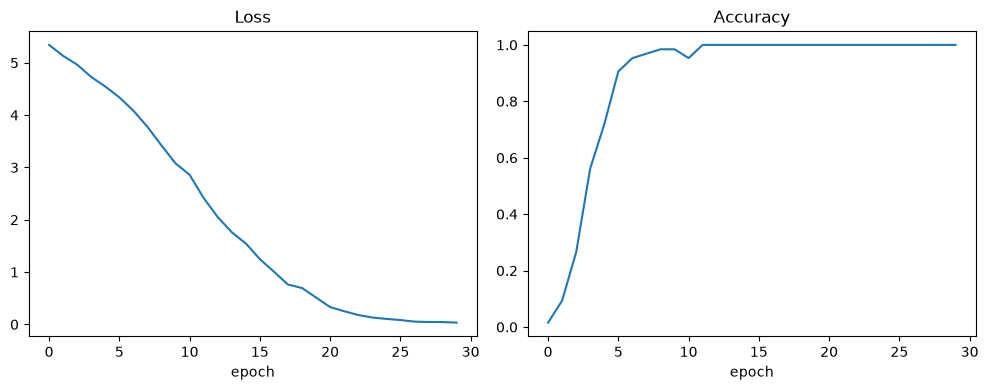

In [40]:
# loss와 정확도 곡선을 그린다.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].plot([loss for loss, acc in small_history])
axes[0].set_title("Loss")
axes[0].set_xlabel("epoch")

axes[1].plot([acc for loss, acc in small_history])
axes[1].set_title("Accuracy")
axes[1].set_xlabel("epoch")

fig.tight_layout()
plt.show()

In [41]:
# 평가 모드에서 같은 64장의 loss와 정확도를 다시 계산한다.
final_loss, final_acc = evaluate(small_model, small_loader, criterion, device)
print(f"평가 모드 loss: {final_loss:.4f}, 정확도: {final_acc:.4f}")

평가 모드 loss: 1.1161, 정확도: 0.9844


## 7. 전체 학습과 검증

- 학습 데이터 4,794장으로 학습하고, 매 epoch 끝에 검증 데이터 1,200장으로 loss와 정확도를 측정한다.
- 검증 정확도가 가장 높은 epoch의 가중치를 체크포인트로 저장한다. 테스트 데이터는 모델 선택에 사용하지 않는다.
- epoch 수와 learning rate는 연습용 값이며, 본 실험의 학습 설정은 팀에서 정한 뒤 기록한다.

In [42]:
# 학습 설정을 정하고 모델과 optimizer를 새로 만든다.
config = {
    "seed": train_seed,
    "epochs": 20,
    "batch_size": 32,
    "optimizer": "AdamW",
    "lr": 1e-4,
    "weight_decay": 0.01,
    "weights": "MobileNet_V3_Large_Weights.IMAGENET1K_V2",
    "torch": str(torch.__version__),
}

set_seed(config["seed"])
student = build_student(num_classes, device)
optimizer = torch.optim.AdamW(student.parameters(), lr=config["lr"], weight_decay=config["weight_decay"])

checkpoint_path = project_root / "outputs" / "baseline_best.pt"
history = []
best_val_acc = 0.0

In [43]:
# epoch마다 학습과 검증을 수행하고 검증 정확도가 최고일 때 체크포인트를 저장한다.
import time

for epoch in range(1, config["epochs"] + 1):
    start = time.time()
    train_loss, train_acc = train_one_epoch(student, train_loader, criterion, optimizer, device)
    val_loss, val_acc = evaluate(student, val_loader, criterion, device)
    history.append({
        "epoch": epoch,
        "train_loss": train_loss, "train_acc": train_acc,
        "val_loss": val_loss, "val_acc": val_acc,
    })

    saved = ""
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save({
            "model_state": student.state_dict(),
            "epoch": epoch,
            "val_acc": val_acc,
            "val_loss": val_loss,
            "config": config,
        }, checkpoint_path)
        saved = " 저장"

    print(
        f"epoch {epoch:2d} | train loss {train_loss:.4f} acc {train_acc:.4f} | "
        f"val loss {val_loss:.4f} acc {val_acc:.4f} | {time.time() - start:.0f}초{saved}"
    )

epoch  1 | train loss 4.9773 acc 0.0488 | val loss 3.9792 acc 0.1625 | 14초 저장
epoch  2 | train loss 2.9530 acc 0.3360 | val loss 2.2264 acc 0.4292 | 14초 저장
epoch  3 | train loss 1.6113 acc 0.5985 | val loss 1.7580 acc 0.5425 | 14초 저장
epoch  4 | train loss 0.9987 acc 0.7518 | val loss 1.5705 acc 0.5867 | 14초 저장
epoch  5 | train loss 0.6770 acc 0.8308 | val loss 1.5233 acc 0.5867 | 14초
epoch  6 | train loss 0.4490 acc 0.8965 | val loss 1.4842 acc 0.6042 | 14초 저장
epoch  7 | train loss 0.2925 acc 0.9428 | val loss 1.4504 acc 0.6133 | 14초 저장
epoch  8 | train loss 0.2136 acc 0.9587 | val loss 1.4621 acc 0.6075 | 14초
epoch  9 | train loss 0.1564 acc 0.9748 | val loss 1.4487 acc 0.6217 | 14초 저장
epoch 10 | train loss 0.1133 acc 0.9821 | val loss 1.4626 acc 0.6208 | 14초
epoch 11 | train loss 0.0843 acc 0.9912 | val loss 1.4275 acc 0.6342 | 14초 저장
epoch 12 | train loss 0.0660 acc 0.9917 | val loss 1.4540 acc 0.6300 | 14초
epoch 13 | train loss 0.0545 acc 0.9937 | val loss 1.4490 acc 0.6333 | 14초
e

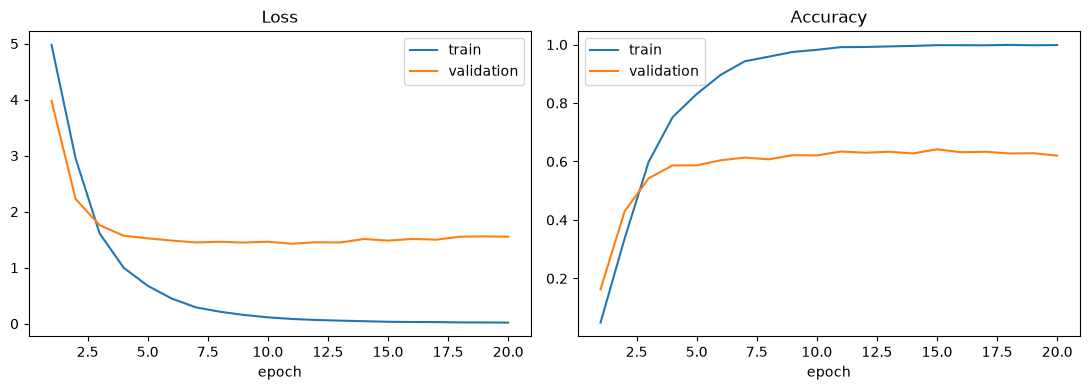

In [44]:
# 학습 곡선을 그려 과적합 여부를 확인한다.
epochs = [row["epoch"] for row in history]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(epochs, [row["train_loss"] for row in history], label="train")
axes[0].plot(epochs, [row["val_loss"] for row in history], label="validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("epoch")
axes[0].legend()

axes[1].plot(epochs, [row["train_acc"] for row in history], label="train")
axes[1].plot(epochs, [row["val_acc"] for row in history], label="validation")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("epoch")
axes[1].legend()

fig.tight_layout()
plt.show()

In [45]:
# 저장한 체크포인트를 새 모델에 복원하여 같은 검증 결과가 나오는지 확인한다.
checkpoint = torch.load(checkpoint_path, map_location=device)

restored = build_student(num_classes, device)
restored.load_state_dict(checkpoint["model_state"])

restored_loss, restored_acc = evaluate(restored, val_loader, criterion, device)
print("저장된 epoch:", checkpoint["epoch"])
print(f"저장 당시 검증 정확도: {checkpoint['val_acc']:.4f}")
print(f"복원 후 검증 정확도: {restored_acc:.4f}")

저장된 epoch: 15
저장 당시 검증 정확도: 0.6417
복원 후 검증 정확도: 0.6417


In [46]:
# 학습 기록을 outputs에 저장한다. 공유할 표와 그림은 이후 docs로 옮긴다.
import json

with open(project_root / "outputs" / "baseline_history.json", "w") as f:
    json.dump({"config": config, "history": history}, f, ensure_ascii=False, indent=2)